# Recovery forecasts for UP5 bonds

Choose a mode in the setup cell and run the sections in order. Each experiment has a calculation cell followed by its tables or figures. Rebuild requires the private UP5 workbooks and TabPFN weights.

| Mode | Execution |
|---|---|
| `review` | Read saved results and display figures. No fitting. |
| `rebuild` | Run each experiment in order and save a new result set. |

| Section | Experiment | Paper |
|---|---|---|
| 1 | Cohort and predictor distributions | Tables 1–2, Figures 4–5 |
| 2 | Target-only point forecasts | §4.3 |
| 3 | Distribution scores and density plots | §4.3, Figures 6–7 |
| 4 | Backbone ablations | §4.3 |
| 5 | Categorical encoding | Figure 8 |
| 6 | Schema expansion | Figure 9 |
| 7 | Saved results | File locations |

The [README](../README.md#where-to-find-each-paper-result) records data access and validation protocols.

## Setup

In [77]:
MODE = "review"  # review | rebuild
from contextlib import redirect_stderr, redirect_stdout
from datetime import datetime
from pathlib import Path
import os
import subprocess
import sys

import pandas as pd
from IPython.display import display, FileLink

if MODE not in {"review", "rebuild"}:
    raise ValueError("Choose review or rebuild.")
cwd = Path.cwd().resolve()
repo = next((p for p in (cwd, *cwd.parents) if (p / "src/experiments/up5").is_dir()), None)
if repo is None:
    raise FileNotFoundError("Start Jupyter from the code repository or its notebooks directory.")
sys.path.insert(0, str(repo / "src"))
data = repo / "data/UP5"
tables = repo / "results/up5"
runs = repo / "outputs/up5_rebuild"
folder = repo / "outputs/up5_historical"  # Earlier versions saved figures here.
if MODE == "review":
    completed = sorted(runs.glob("*/COMPLETE"))
    if completed:
        tables = completed[-1].parent
        folder = tables / "historical"
else:
    required = [f"{split}_{kind}2.xlsx" for split in ("train", "test") for kind in ("features", "labels")]
    missing = [name for name in required if not (data / name).is_file()]
    if missing:
        raise FileNotFoundError(f"Missing UP5 workbooks: {missing}")
    import tabpfn
    from simulation.notebook_reporting import quiet_epochs
    tables = runs / datetime.now().strftime("%Y%m%d-%H%M%S-%f")
    tables.mkdir(parents=True)
    folder = tables / "historical"

from functools import partial
from experiments.up5.notebook_reporting import fit_step as run_step, show_table, build_figures, show_figures, complete_run
from simulation.notebook_reporting import show_figure
fit_step = partial(run_step, tables)
show = partial(show_table, tables)

print(f"Mode: {MODE} | result tables: {tables.relative_to(repo)}")
from simulation.table_reporting import present_table


Mode: review | result tables: results/up5


## 1. Cohort and predictor distributions

This cell calculates descriptive statistics and Figures 4–5. It fits no model.

In [80]:
if MODE == "rebuild":
    from experiments.up5.cohort_summary import recovery_summary
    recovery_summary(data).to_csv(tables / "recovery-summary.csv", index_label="UP5 cohort")

if MODE == "rebuild":
    build_figures(repo, folder, "descriptive")

### Cohort summary and UP5 panels

,count,mean,std,skew
UP5 cohort,,,,
Training,1293.0,0.4835,0.3295,0.3379
Evaluation,432.0,0.4876,0.3388,0.3144
Combined,1725.0,0.4845,0.3318,0.3318


Saved manuscript figure: rr_dist_up5.png


/Users/christophergerling/Documents/Revision TL Paper/Code Repository/results/up5/paper_figures/rr_dist_up5.png

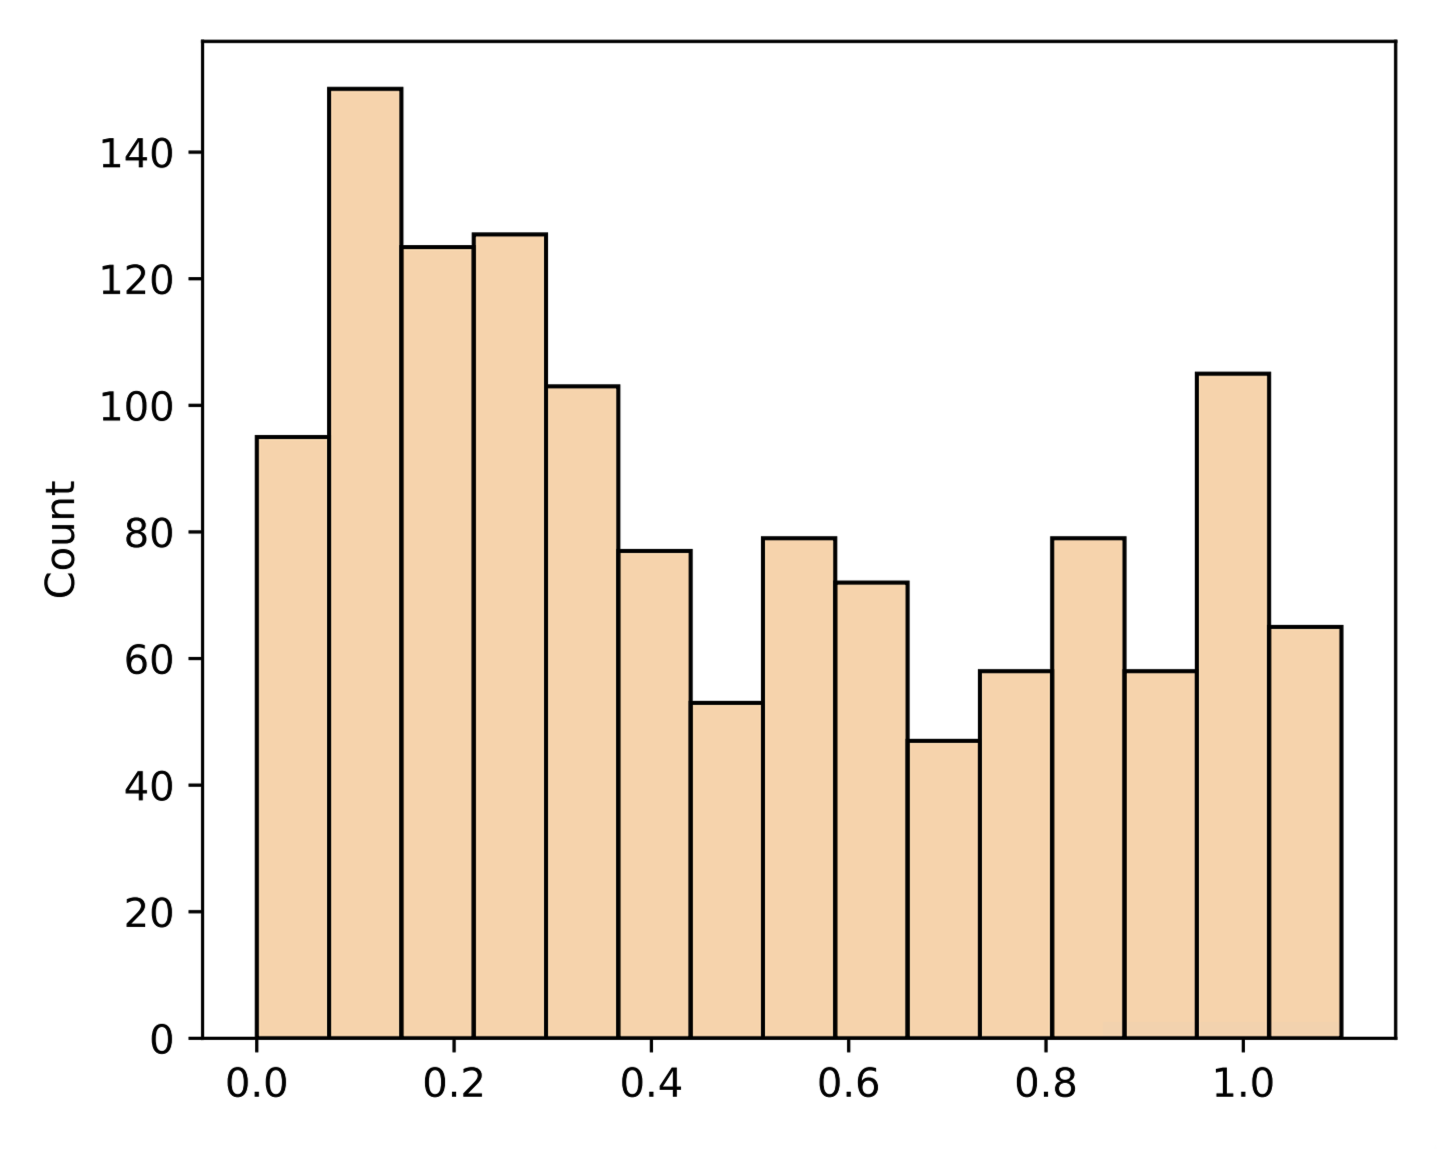

Saved manuscript figure: correlation_heatmap_up5.png


/Users/christophergerling/Documents/Revision TL Paper/Code Repository/results/up5/paper_figures/correlation_heatmap_up5.png

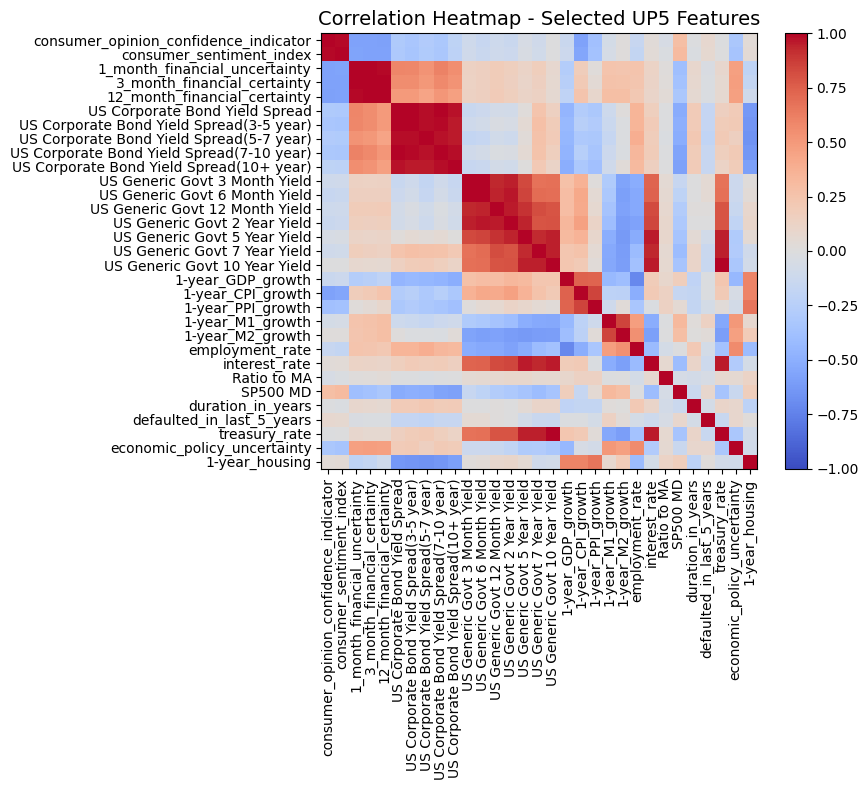

In [83]:
show("recovery-summary.csv")
show_figures(repo, folder, ["rr_dist_up5.png", "correlation_heatmap_up5.png"], MODE)

## 2. Target-only point forecasts

Training mean, XGBoost, MLP, FT-MDN-T and TabPFN use the same fitting and evaluation observations.

In [86]:
if MODE == "rebuild":
    from experiments.up5.target_only import run_benchmark
    fit_step("Target-only point forecasts", run_benchmark, data, tables)

### Point forecast scores

In [89]:
show("scores.csv")

,r2,mae,seconds,n_fit,n_validation
model,,,,,
Training mean,-0.0029,0.2967,0.0006,1034,259
XGBoost,0.5006,0.1478,0.6638,1034,259
MLP,0.4661,0.1817,1.4213,1034,259
FT–MDN–T,0.4108,0.1848,3174.7538,1034,259
TabPFN,0.5449,0.1630,799.7607,1034,259


## 3. Predictive distributions

Score the FT-MDN-T forecast saved in Section 2, Gaussian ridge and the empirical recovery distribution. This cell adds no FT-MDN-T training.

In [92]:
if MODE == "rebuild":
    from experiments.up5.distribution import compare
    from experiments.up5.cohort_summary import tail_probabilities
    density = pd.DataFrame(fit_step("Density scores", compare, data, tables)).T
    density.to_csv(tables / "density-scores.csv", index_label="model")
    tail_probabilities(tables).to_csv(tables / "tails.csv", index_label="measure")

### Distribution scores, coverage and tails

In [95]:
show("density-scores.csv")
show("tails.csv")

,CRPS,NLL,coverage80,width80
model,,,,
FT–MDN–T,0.1308,-0.2815,0.7222,0.4566
Gaussian ridge,0.1542,0.1352,0.7940,0.6714
Training empirical,0.1939,NaN,NaN,NaN


,Below zero (%),Above par (%)
measure,,
Mean forecast probability,1.0743,6.7688
Observed frequency,0.0000,10.8796


### Individual and portfolio density figures

In rebuild, this cell fits the illustration model once for Figures 6–7. These figures use the supplied evaluation set for validation. The benchmarks above reserve validation rows within the training set.

In [98]:
if MODE == "rebuild":
    build_figures(repo, folder, "density")

### Figure 6 · Individual bond recoveries

Saved manuscript figure: mdn_dist_sample_1.pdf


/Users/christophergerling/Documents/Revision TL Paper/Code Repository/results/up5/paper_figures/mdn_dist_sample_1.pdf

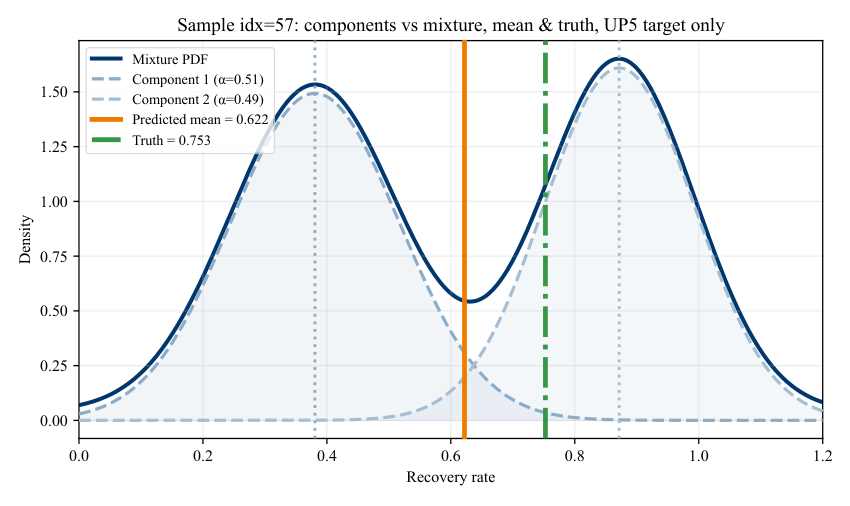

Saved manuscript figure: mdn_dist_sample_2.pdf


/Users/christophergerling/Documents/Revision TL Paper/Code Repository/results/up5/paper_figures/mdn_dist_sample_2.pdf

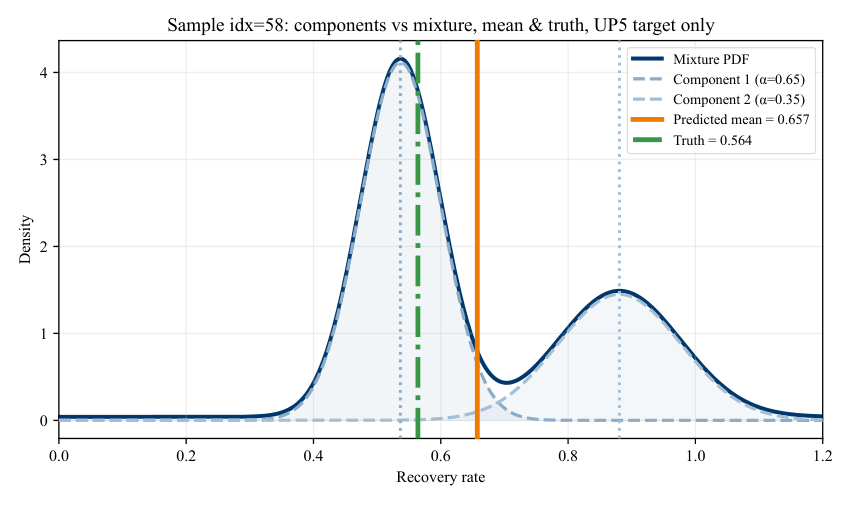

Saved manuscript figure: mdn_dist_sample_3.pdf


/Users/christophergerling/Documents/Revision TL Paper/Code Repository/results/up5/paper_figures/mdn_dist_sample_3.pdf

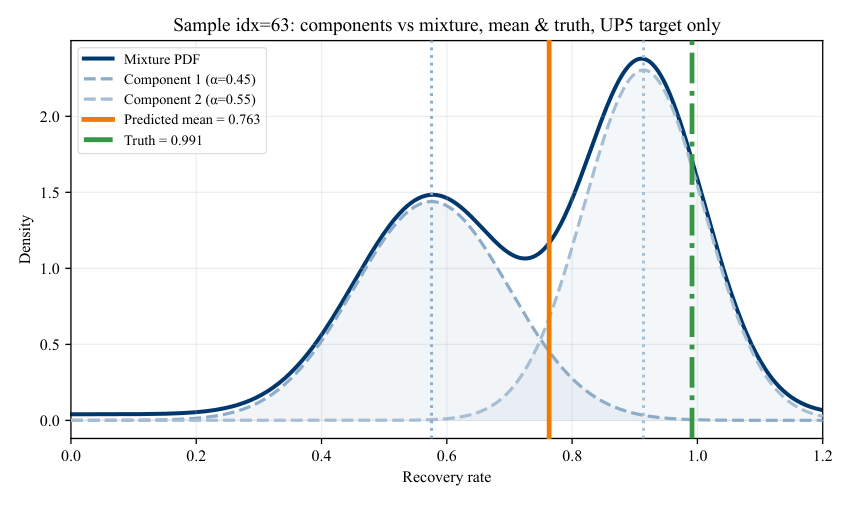

Saved manuscript figure: mdn_dist_sample_4.pdf


/Users/christophergerling/Documents/Revision TL Paper/Code Repository/results/up5/paper_figures/mdn_dist_sample_4.pdf

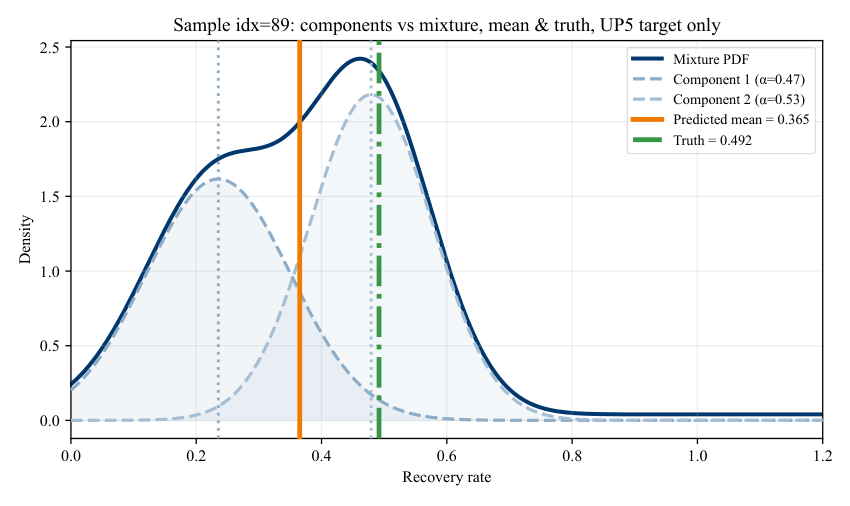

In [101]:
show_figures(repo, folder, [f"mdn_dist_sample_{i}.pdf" for i in range(1, 5)], MODE)

### Figure 7 · Portfolio recoveries

Saved manuscript figure: up5_ft_mdn_density_side_by_side.pdf


/Users/christophergerling/Documents/Revision TL Paper/Code Repository/results/up5/paper_figures/up5_ft_mdn_density_side_by_side.pdf

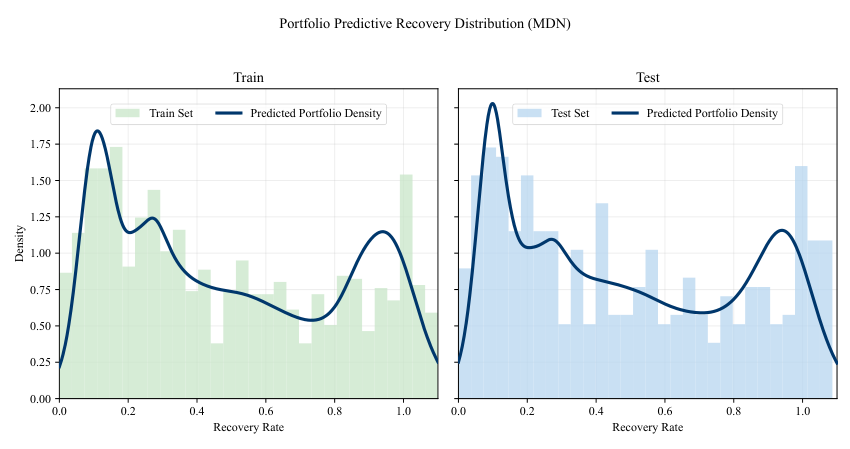

In [104]:
show_figures(repo, folder, ["up5_ft_mdn_density_side_by_side.pdf"], MODE)

## 4. Backbone comparisons

The first comparison uses 317 encoded predictors. The second holds the native tokenizer design fixed for 155 numerical and nine categorical fields.

In [107]:
if MODE == "rebuild":
    from experiments.up5.encoded_backbones import compare_backbones
    fit_step("Encoded backbone comparison", compare_backbones, data, tables)

### Encoded predictors · Transformer versus MLP mixture head

In [110]:
show("mdn-backbones.csv")

,R2,MAE,CRPS,NLL,coverage80,width80
FT–MDN–T,0.4108,0.1848,0.1308,-0.2815,0.7222,0.4566
MLP-MDN,0.4774,0.1716,0.1243,-0.3377,0.7014,0.3959


### Native tokens · Calculation

In [113]:
if MODE == "rebuild":
    from experiments.up5.native_backbones import compare_native
    native = fit_step("Native-token backbone comparison", compare_native, data, tables / "native")
    native.to_csv(tables / "native-backbones.csv")

### Native tokens · Scores and parameter counts

In [116]:
show("native-backbones.csv")

,parameters,epoch,val_R2,R2,MAE,CRPS,NLL,coverage80,width80,seconds
model,,,,,,,,,,
FT–MDN–T,408631,59,0.4152,0.3983,0.1817,0.1334,-0.2704,0.6898,0.4012,909.2893
FT pooled-MLP–MDN,64623,73,0.3684,0.3236,0.2112,0.1483,-0.0572,0.6806,0.5297,108.1440


## 5. Categorical encoding

Figure 8 compares dummy expansion and categorical embeddings over 15 seeds per encoding. Rebuild fits these two series and saves their validation histories.

In [119]:
if MODE == "rebuild":
    build_figures(repo, folder, "encoding")

### Figure 8 · Encoding comparison

Saved manuscript figure: ft_mdn_transformer_cat_vs_dummy.pdf


/Users/christophergerling/Documents/Revision TL Paper/Code Repository/results/up5/paper_figures/ft_mdn_transformer_cat_vs_dummy.pdf

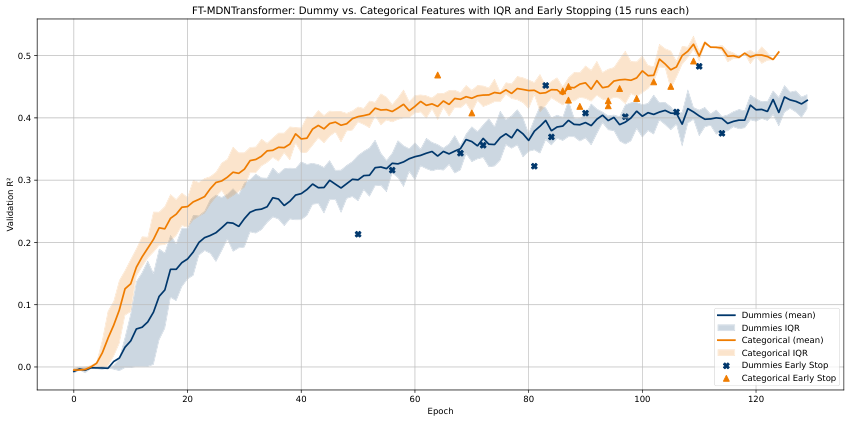

In [122]:
show_figures(repo, folder, ["ft_mdn_transformer_cat_vs_dummy.pdf"], MODE)

## 6. Schema expansion within UP5

Ten seeds, 80 epochs per phase, 36 shared predictors expanding to 164 native predictors. All weights remain trainable. Validation selects checkpoints. Review uses the explicitly selected saved run independently of the benchmark tables.

In [125]:
SCHEMA_REVIEW_RUN = "cbd7e60cc586fc18"  # Completed 10-seed run; None selects the latest.
SCHEMA_SEEDS = tuple(range(10))
SCHEMA_EPOCHS = 80

from importlib import reload
from experiments.up5 import schema_expansion
schema_expansion = reload(schema_expansion)
from simulation.notebook_reporting import show_figure

schema_root = repo / "outputs/up5_schema_expansion"
if MODE == "rebuild":
    schema_root = tables / "schema_expansion"
if MODE == "rebuild":
    schema_run = schema_expansion.run(data, schema_root, seeds=SCHEMA_SEEDS, epochs=SCHEMA_EPOCHS)
elif SCHEMA_REVIEW_RUN is not None:
    schema_run = schema_root / SCHEMA_REVIEW_RUN
    if not (schema_run / "COMPLETE").is_file():
        raise FileNotFoundError(f"Completed schema run missing: {schema_run}. Select an available run explicitly.")
else:
    # Include schema experiments saved within a complete full rebuild.
    candidates = list(schema_root.glob("*/COMPLETE")) + list((tables / "schema_expansion").glob("*/COMPLETE"))
    schema_run = max(candidates, key=lambda p: p.stat().st_mtime).parent if candidates else None

### Figure 9 · Adaptation curve and scores

The plot shows epochs 1–80. The table includes the pre-update values and checks preservation of predictions with added tokens masked.

Schema-expansion results: outputs/up5_schema_expansion/cbd7e60cc586fc18
Benchmark tables: results/up5


,seed,pre_start,pre_last,pre_selected,pre_epoch,fine_start,fine_first,fine_last,fine_selected,fine_epoch,shared_prediction_max_error,pre_assessment,fine_assessment,seconds
0,0,-0.01504,0.2838,0.3111,76,-0.38,0.2531,0.3744,0.4984,23,2.682e-07,0.4174,0.4731,2016
1,1,-0.3313,0.2547,0.2914,66,-1.416,0.2474,0.405,0.454,66,3.576e-07,0.3584,0.4362,1920
2,2,-0.03185,0.2902,0.304,72,-0.3164,0.2011,0.3654,0.4056,54,3.874e-07,0.3672,0.4204,1861
3,3,-0.003567,0.3453,0.3453,80,-0.7662,0.2616,0.4509,0.4539,74,2.384e-07,0.3602,0.4577,1892
4,4,-0.005663,0.362,0.362,80,-1.07,0.0803,0.3892,0.3953,78,2.384e-07,0.3684,0.4362,1864
5,5,-0.02567,0.2775,0.2867,73,-0.7353,0.09536,0.2952,0.3483,71,4.172e-07,0.3967,0.4364,1857
6,6,-0.02265,0.2859,0.3593,78,0.003642,0.27,0.4098,0.4758,74,2.98e-07,0.3916,0.4921,1878
7,7,-0.1243,0.2129,0.2975,44,-0.5643,0.2547,0.3825,0.4206,35,2.384e-07,0.3471,0.4047,1928
8,8,-0.01518,0.2607,0.2884,67,-0.8112,0.1232,0.3326,0.4134,50,2.98e-07,0.3539,0.3735,1877
9,9,-0.1819,0.3156,0.3554,78,-0.6856,0.234,0.3636,0.4219,50,6.557e-07,0.3671,0.4232,1885


,pre_start,pre_last,pre_selected,fine_start,fine_first,fine_last,fine_selected,pre_assessment,fine_assessment
mean,-0.07571,0.2889,0.3201,-0.6741,0.2021,0.3769,0.4287,0.3728,0.4354
std,0.1073,0.04364,0.03155,0.3977,0.07382,0.04281,0.04322,0.02207,0.0338


/Users/christophergerling/Documents/Revision TL Paper/Code Repository/outputs/up5_schema_expansion/cbd7e60cc586fc18/ft_mdn_transformer_schema_expansion.pdf

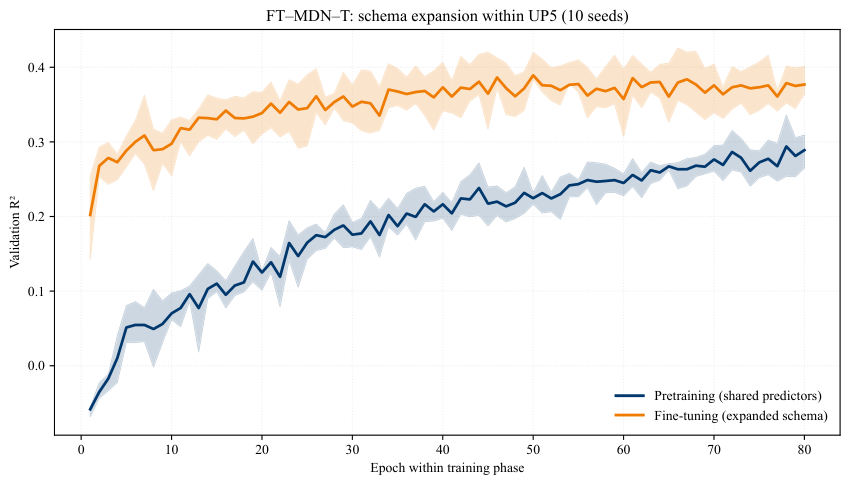

Run records: outputs/up5_schema_expansion/cbd7e60cc586fc18


In [128]:
if schema_run is None:
    print("No completed schema-expansion run. Rebuild generates Figure 9.")
else:
    print(f"Schema-expansion results: {schema_run.relative_to(repo)}", flush=True)
    print(f"Benchmark tables: {tables.relative_to(repo)}", flush=True)
    figure = schema_expansion.plot(schema_run)
    summary = pd.read_csv(schema_run / "summary.csv")
    present_table(summary)
    present_table(summary[["pre_start", "pre_last", "pre_selected", "fine_start", "fine_first",
                     "fine_last", "fine_selected", "pre_assessment", "fine_assessment"]].agg(["mean", "std"]))
    show_figure(figure)
    print(f"Run records: {schema_run.relative_to(repo)}")

## 7. Saved results

A rebuild is marked complete only after all experiment sections have produced their required files.

In [131]:
if MODE == "rebuild":
    complete_run(tables, folder, schema_run)
print(f"Benchmark tables: {tables.relative_to(repo)}")
print(f"Distribution and encoding figures: {folder.relative_to(repo)}")
if schema_run is not None:
    print(f"Schema-expansion records: {schema_run.relative_to(repo)}")
for path in sorted(tables.glob("*.csv")):
    present_table(FileLink(os.path.relpath(path)))

Benchmark tables: results/up5
Distribution and encoding figures: outputs/up5_historical
Schema-expansion records: outputs/up5_schema_expansion/cbd7e60cc586fc18


/Users/christophergerling/Documents/Revision TL Paper/Code Repository/results/up5/density-scores.csv

/Users/christophergerling/Documents/Revision TL Paper/Code Repository/results/up5/mdn-backbones.csv

/Users/christophergerling/Documents/Revision TL Paper/Code Repository/results/up5/native-backbones.csv

/Users/christophergerling/Documents/Revision TL Paper/Code Repository/results/up5/recovery-summary.csv

/Users/christophergerling/Documents/Revision TL Paper/Code Repository/results/up5/scores.csv

/Users/christophergerling/Documents/Revision TL Paper/Code Repository/results/up5/tails.csv